In [1]:
from functools import partial
import logging

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.baselines import decay_forecast, mean_forecast, persistence_forecast
from cwfc.evaluation import backtest
from cwfc.split import split_holdout
from cwfc.targets import build_targets

logging.basicConfig(level=logging.INFO)
readings = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
train, holdout_timestamps = split_holdout(build_targets(readings))

TARGET = "aggregate_cpu_utilization"
forecasters = {
    "persistence": persistence_forecast,
    "mean (all)": mean_forecast,
    "decay": decay_forecast,
    "mean (last 12)": partial(mean_forecast, window=12),
}
results = pd.concat(
    {name: backtest(train, f, TARGET) for name, f in forecasters.items()}, names=["model"]
).reset_index(level=0)
results["abs_err"] = (results["actual"] - results["forecast"]).abs()
results["sq_err"] = (results["actual"] - results["forecast"]) ** 2

INFO:cwfc.targets:Dropped 0 of 1340000 rows


In [2]:
per_fold = results.groupby(["model", "fold"]).agg(
    mae=("abs_err", "mean"), rmse=("sq_err", lambda s: s.mean() ** 0.5)
)
summary = per_fold.groupby("model").agg(mae=("mae", "mean"), mae_std=("mae", "std"), rmse=("rmse", "mean"))
summary["vs_persistence"] = 1 - summary["mae"] / summary.loc["persistence", "mae"]
summary.round(3)

,mae,mae_std,rmse,vs_persistence
model,,,,
decay,0.201,0.060,0.230,0.065
mean (all),0.209,0.056,0.238,0.030
mean (last 12),0.260,0.100,0.288,-0.206
persistence,0.215,0.096,0.251,0.000


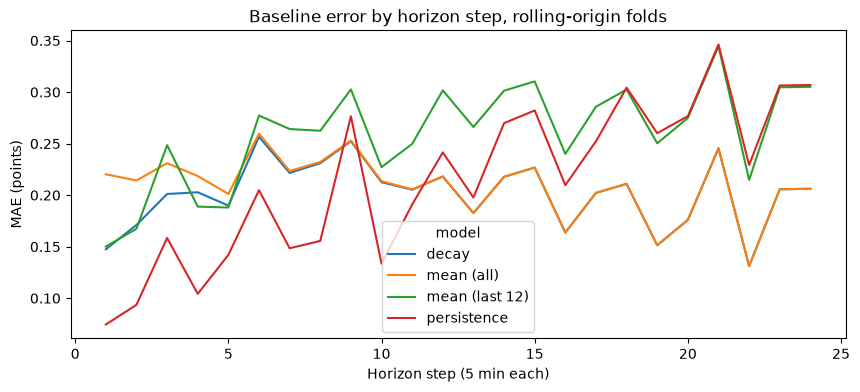

In [3]:
per_step = results.groupby(["model", "step"])["abs_err"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4))
per_step.plot(ax=ax)
ax.set_xlabel("Horizon step (5 min each)")
ax.set_ylabel("MAE (points)")
ax.set_title("Baseline error by horizon step, rolling-origin folds")
plt.show()

In [4]:
(per_step["mean (all)"] < per_step["persistence"]).idxmax()

np.int64(9)

Finding: Over 7 rolling-origin folds, the full-history mean is the best baseline (MAE 0.209), but only 3% better than persistence (0.215). It is also the most stable across folds (std 0.056 vs 0.096). The 12-step moving average is worst (0.260, 21% worse than persistence): it is both noisy and partly persistent.

By horizon step, persistence is far better at the first step (MAE 0.074 vs 0.220) but degrades to 0.307 by step 24, while the mean stays roughly flat. The mean overtakes persistence at step 9 (45 minutes), confirming the autocorrelation analysis.

Finding: The decay model (start at the last value, move towards the mean at rate φ^h, with φ the lag-1 autocorrelation of the training data) is the best overall: MAE 0.201, 6.5% better than persistence and about 4% better than the mean. The gain is small relative to fold-to-fold variation (std 0.060), but consistent: it matches or beats the mean in all 7 folds.

At step 1 it is worse than persistence (0.147 vs 0.074): it already pulls the forecast 30% towards the long-run mean, which may not match the current local level (for example during the hour 4–6 bump).